In [1]:
# GPU et Google Drive
import tensorflow as tf
print("TensorFlow", tf.__version__, "| GPU :", tf.config.list_physical_devices("GPU"))

from google.colab import drive
drive.mount("/content/drive")

import os
os.chdir("/content/drive/MyDrive/cocoa-bean-classification")
os.makedirs("results/dl", exist_ok=True)
os.makedirs("models", exist_ok=True)
print("Dossier de travail :", os.getcwd(), "|", os.listdir("."))

TensorFlow 2.21.0 | GPU : [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Mounted at /content/drive
Dossier de travail : /content/drive/MyDrive/cocoa-bean-classification | ['data', 'results', 'models', '06_deep_learning.ipynb', '07_ablation.ipynb']


In [2]:
# données et découpage

import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import keras
from keras import layers
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             matthews_corrcoef, cohen_kappa_score, roc_auc_score, confusion_matrix)

donnees = np.load("data/donnees_feves.npz")
X = donnees["X"].astype("float32")        # pixels de 0 à 255 : chaque modèle gère sa normalisation
y = donnees["y"]
df = pd.read_csv("results/02_decoupage.csv")
classes = ["category 1", "category 2", "category 3"]

idx_app = np.where((df["partition"] == "train") & (df["pli"] != 0))[0]   # apprentissage
idx_val = np.where(df["pli"] == 0)[0]                                    # validation (arrêt précoce)
idx_test = np.where(df["partition"] == "test")[0]
print(f"Apprentissage : {len(idx_app)} | Validation : {len(idx_val)} | Test : {len(idx_test)}")

poids = compute_class_weight("balanced", classes=np.arange(3), y=y[idx_app])
poids_classes = dict(enumerate(poids))
print("Poids des classes :", {classes[k]: round(v, 2) for k, v in poids_classes.items()})

Apprentissage : 2861 | Validation : 715 | Test : 894
Poids des classes : {'category 1': np.float64(0.78), 'category 2': np.float64(0.89), 'category 3': np.float64(1.7)}


In [3]:
# l’augmentation et l’évaluation (communes à tous les modèles)

def bloc_augmentation():
    return keras.Sequential([
        layers.RandomFlip("horizontal_and_vertical"),
        layers.RandomRotation(0.25, fill_mode="nearest"),
        layers.RandomTranslation(0.1, 0.1, fill_mode="nearest"),
        layers.RandomBrightness(0.1, value_range=(0, 255)),
    ], name="augmentation")

def evaluer(y_vrai, proba):
    """Toutes les métriques du sujet, à partir des probabilités prédites."""
    pred = proba.argmax(axis=1)
    return {
        "Accuracy": accuracy_score(y_vrai, pred),
        "Precision (macro)": precision_score(y_vrai, pred, average="macro"),
        "Recall (macro)": recall_score(y_vrai, pred, average="macro"),
        "F1 (macro)": f1_score(y_vrai, pred, average="macro"),
        "MCC": matthews_corrcoef(y_vrai, pred),
        "Kappa": cohen_kappa_score(y_vrai, pred),
        "ROC-AUC": roc_auc_score(y_vrai, proba, multi_class="ovr", average="macro"),
    }

In [4]:
# la fonction d’entraînement

def entrainer(construire_modele, nom, graine=42, epochs=80, lr=1e-3, batch=64):
    keras.utils.set_random_seed(graine)          # rend l'entraînement reproductible
    modele = construire_modele()
    modele.compile(optimizer=keras.optimizers.Adam(lr),
                   loss="sparse_categorical_crossentropy", metrics=["accuracy"])
    rappels = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=10, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=4),
    ]
    debut = time.time()
    historique = modele.fit(X[idx_app], y[idx_app], validation_data=(X[idx_val], y[idx_val]),
                            epochs=epochs, batch_size=batch, class_weight=poids_classes,
                            callbacks=rappels, verbose=0)
    duree = time.time() - debut

    debut = time.time()
    proba = modele.predict(X[idx_test], verbose=0)
    temps_inference = (time.time() - debut) / len(idx_test) * 1000     # ms par image

    resultat = {"Modèle": nom, "Graine": graine, **evaluer(y[idx_test], proba),
                "Paramètres": modele.count_params(), "Époques": len(historique.history["loss"]),
                "Temps d'entraînement (s)": duree, "Inférence (ms/image)": temps_inference}
    return modele, historique.history, proba, resultat

In [5]:
#Briques communes

def conv_bn_relu(x, filtres, taille=3, dilatation=1):
    x = layers.Conv2D(filtres, taille, padding="same", dilation_rate=dilatation, use_bias=False)(x)
    x = layers.BatchNormalization()(x)
    return layers.Activation("relu")(x)

def extracteur_cnn(x):
    """Le CNN de M1 sans sa tête de classification : 60x60x3 -> 7x7x128."""
    for filtres in [32, 64, 128]:
        x = conv_bn_relu(x, filtres)
        x = conv_bn_relu(x, filtres)
        x = layers.MaxPooling2D()(x)
    return x

class AjoutPosition(layers.Layer):
    """Ajoute à chaque token un vecteur de position appris."""
    def build(self, forme):
        self.positions = self.add_weight(shape=(1, forme[1], forme[2]),
                                         initializer="random_normal", name="positions")
    def call(self, x):
        return x + self.positions

def bloc_transformer(x, tetes=4, dim=128, dim_mlp=256, dropout=0.1):
    # 1) Attention : chaque zone regarde toutes les autres
    y = layers.LayerNormalization()(x)
    y = layers.MultiHeadAttention(num_heads=tetes, key_dim=dim // tetes, dropout=dropout)(y, y)
    x = layers.Add()([x, y])                         # connexion résiduelle
    # 2) Petit réseau dense appliqué à chaque zone
    y = layers.LayerNormalization()(x)
    y = layers.Dense(dim_mlp, activation="gelu")(y)
    y = layers.Dropout(dropout)(y)
    y = layers.Dense(dim)(y)
    return layers.Add()([x, y])                      # connexion résiduelle

def tracer_courbes(hist, code, nom, fin_phase1=None):
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    for ax, cle, titre in [(axes[0], "loss", "Perte (loss)"), (axes[1], "accuracy", "Accuracy")]:
        ax.plot(hist[cle], label="Apprentissage")
        ax.plot(hist["val_" + cle], label="Validation")
        if fin_phase1:
            ax.axvline(fin_phase1 - 0.5, color="gray", linestyle="--", label="Début du fine-tuning")
        ax.set_title(titre); ax.set_xlabel("Époque"); ax.legend()
    plt.suptitle(f"{nom} : courbes d'apprentissage")
    plt.tight_layout()
    plt.savefig(f"results/dl/06_courbes_{code}.png", dpi=150)
    plt.show()

In [6]:
# M4 et M5

def bloc_multi_echelle(x, filtres):
    b3 = conv_bn_relu(x, filtres, 3)                   # détails fins
    b5 = conv_bn_relu(x, filtres, 5)                   # structures intermédiaires
    b7 = conv_bn_relu(x, filtres, 3, dilatation=3)     # structures globales (champ 7x7)
    x = layers.Concatenate()([b3, b5, b7])
    x = conv_bn_relu(x, filtres * 2, 1)                # fusion des trois échelles
    return layers.MaxPooling2D()(x)

def construire_multi_echelle():
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    x = conv_bn_relu(x, 32)
    for filtres in [32, 64, 64]:
        x = bloc_multi_echelle(x, filtres)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(entree, layers.Dense(3, activation="softmax")(x), name="M4_Multi_echelle")

def construire_cnn_transformer():
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    x = extracteur_cnn(x)                    # (7, 7, 128)
    x = layers.Reshape((-1, 128))(x)         # 49 tokens de dimension 128
    x = AjoutPosition()(x)
    for _ in range(2):
        x = bloc_transformer(x)
    x = layers.LayerNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)   # moyenne des 49 tokens
    x = layers.Dropout(0.3)(x)
    return keras.Model(entree, layers.Dense(3, activation="softmax")(x), name="M5_CNN_Transformer")

In [7]:
#la couche ANFIS

from keras import ops

class CoucheANFIS(layers.Layer):
    """Système d'inférence neuro-flou de Takagi-Sugeno (premier ordre)."""

    def __init__(self, nb_regles=12, nb_sorties=3, **kwargs):
        super().__init__(**kwargs)
        self.nb_regles = nb_regles
        self.nb_sorties = nb_sorties

    def build(self, forme):
        d = forme[-1]                                          # nombre d'entrées floues
        # Couche 1 : un centre et une largeur par règle et par entrée
        self.centres = self.add_weight(shape=(self.nb_regles, d), initializer="random_normal", name="centres")
        self.log_sigmas = self.add_weight(shape=(self.nb_regles, d), initializer="zeros", name="log_sigmas")
        # Couche 4 : conséquents linéaires y = A.x + b pour chaque règle
        self.A = self.add_weight(shape=(self.nb_regles, d, self.nb_sorties), initializer="glorot_uniform", name="A")
        self.b = self.add_weight(shape=(self.nb_regles, self.nb_sorties), initializer="zeros", name="b")

    def forces(self, x):
        """Couches 1 à 3 : force normalisée de chaque règle, forme (lot, nb_regles)."""
        ecart = (ops.expand_dims(x, 1) - self.centres) / ops.exp(self.log_sigmas)
        exposant = -0.5 * ops.sum(ops.square(ecart), axis=-1)  # log du produit des gaussiennes
        return ops.softmax(exposant, axis=-1)                   # normalisation w / somme(w)

    def call(self, x):
        w = self.forces(x)                                                # couches 1 à 3
        y_regles = ops.einsum("bd,rdk->brk", x, self.A) + self.b         # couche 4
        return ops.sum(ops.expand_dims(w, -1) * y_regles, axis=1)        # couche 5

    def get_config(self):
        config = super().get_config()
        config.update(nb_regles=self.nb_regles, nb_sorties=self.nb_sorties)
        return config

# Étape 7 : Étude d'ablation
Objectif : mesurer la contribution de chaque composant de l'architecture (espaces de couleur, extraction multi-échelle, apprentissage siamois, Transformer, ANFIS).

**Protocole :** mêmes partitions, même augmentation, mêmes poids de classe, même arrêt précoce et mêmes 3 graines (42, 7, 2026) qu'à l'étape 6. Les variantes A1, A3, A4 et A6 correspondent exactement aux modèles M1, M4, M6 et M7 de l'étape 6 : leurs résultats sont réutilisés. Les variantes A2, A5 et A7 sont entraînées ici.

In [8]:
#conversion des espaces de couleur dans le modèle (pour A2)

import tensorflow as tf

class ConversionCouleurs(layers.Layer):
    """RGB (0-255) -> 9 canaux entre 0 et 1 : RGB, HSV (teinte tournée de 180°) et LAB."""
    def call(self, x):
        rgb = ops.clip(x / 255.0, 0.0, 1.0)

        # HSV, avec la même rotation de la teinte qu'à l'étape 3
        hsv = tf.image.rgb_to_hsv(rgb)
        teinte = (hsv[..., 0:1] + 0.5) % 1.0
        hsv = ops.concatenate([teinte, hsv[..., 1:]], axis=-1)

        # LAB : RGB -> RGB linéaire -> XYZ -> LAB (formules standard, illuminant D65)
        lineaire = ops.where(rgb <= 0.04045, rgb / 12.92, ops.power((rgb + 0.055) / 1.055, 2.4))
        M = ops.convert_to_tensor([[0.412453, 0.357580, 0.180423],
                                   [0.212671, 0.715160, 0.072169],
                                   [0.019334, 0.119193, 0.950227]], dtype="float32")
        xyz = ops.einsum("...c,dc->...d", lineaire, M) / ops.convert_to_tensor([0.950456, 1.0, 1.088754])
        f = ops.where(xyz > 0.008856, ops.power(ops.maximum(xyz, 1e-6), 1 / 3), 7.787 * xyz + 16 / 116)
        L = 116 * f[..., 1:2] - 16
        a = 500 * (f[..., 0:1] - f[..., 1:2])
        b = 200 * (f[..., 1:2] - f[..., 2:3])
        lab = ops.concatenate([L / 100, (a + 128) / 255, (b + 128) / 255], axis=-1)

        return ops.concatenate([rgb, hsv, lab], axis=-1)

In [9]:
#Les trois nouvelles variantes

def tete_anfis(x, nb_entrees_floues=8, nb_regles=12):
    """Réduction à 8 caractéristiques, puis classification neuro-floue (identique à M8)."""
    x = layers.Dense(nb_entrees_floues, name="entrees_floues")(x)
    x = layers.BatchNormalization(name="normalisation_floue")(x)
    x = CoucheANFIS(nb_regles, 3, name="anfis")(x)
    return layers.Activation("softmax")(x)

def construire_cnn_couleurs():                    # A2 : M1 avec 9 canaux de couleur
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = ConversionCouleurs()(x)
    for filtres in [32, 64, 128]:
        x = conv_bn_relu(x, filtres)
        x = conv_bn_relu(x, filtres)
        x = layers.MaxPooling2D()(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(entree, layers.Dense(3, activation="softmax")(x), name="A2_CNN_couleurs")

def construire_cnn_anfis():                       # A5 : M1 avec une tête ANFIS
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    x = extracteur_cnn(x)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(entree, tete_anfis(x), name="A5_CNN_ANFIS")

def construire_complet():                         # A7 : CNN multi-échelle + Transformer + ANFIS
    entree = keras.Input(shape=(60, 60, 3))
    x = bloc_augmentation()(entree)
    x = layers.Rescaling(1 / 255)(x)
    x = conv_bn_relu(x, 32)
    for filtres in [32, 64, 64]:
        x = bloc_multi_echelle(x, filtres)        # 60 -> 30 -> 15 -> 7, 128 canaux en sortie
    x = layers.Reshape((-1, 128))(x)              # 49 tokens
    x = AjoutPosition()(x)
    for _ in range(2):
        x = bloc_transformer(x)
    x = layers.LayerNormalization()(x)
    x = layers.GlobalAveragePooling1D()(x)
    x = layers.Dropout(0.3)(x)
    return keras.Model(entree, tete_anfis(x), name="A7_complet")

In [10]:
#Une cellule de vérification

necessaires = ["entrainer", "evaluer", "bloc_augmentation", "conv_bn_relu", "extracteur_cnn",
               "AjoutPosition", "bloc_transformer", "bloc_multi_echelle", "CoucheANFIS",
               "ConversionCouleurs", "construire_cnn_couleurs", "construire_cnn_anfis", "construire_complet"]
manquantes = [f for f in necessaires if f not in globals()]
print("Fonctions manquantes :", manquantes if manquantes else "aucune, tout est prêt")

Fonctions manquantes : aucune, tout est prêt


In [11]:
#La boucle d’entraînement

import gc

NOUVELLES = {
    "A2 – CNN + espaces de couleur": construire_cnn_couleurs,
    "A5 – CNN + ANFIS": construire_cnn_anfis,
    "A7 – Architecture complète": construire_complet,
}
fichier = "results/dl/07_ablation_nouvelles_variantes.csv"
res_ablation = pd.read_csv(fichier).to_dict("records") if os.path.exists(fichier) else []

debut_total = time.time()
for graine in [42, 7, 2026]:
    for nom, construire in NOUVELLES.items():
        if (nom, graine) in {(r["Modèle"], int(r["Graine"])) for r in res_ablation}:
            continue
        modele, hist, proba, res = entrainer(construire, nom, graine=graine)
        res_ablation.append(res)
        pd.DataFrame(res_ablation).to_csv(fichier, index=False)
        if nom.startswith("A7") and graine == 42:
            modele.save("models/A7_architecture_complete.keras")
        print(f"[{(time.time() - debut_total) / 60:4.0f} min] {nom} | graine {graine} | F1 = {res['F1 (macro)']:.4f}")
        keras.backend.clear_session()
        gc.collect()

[   3 min] A2 – CNN + espaces de couleur | graine 42 | F1 = 0.9261
[   6 min] A5 – CNN + ANFIS | graine 42 | F1 = 0.9386
[  11 min] A7 – Architecture complète | graine 42 | F1 = 0.9498
[  14 min] A2 – CNN + espaces de couleur | graine 7 | F1 = 0.9410
[  17 min] A5 – CNN + ANFIS | graine 7 | F1 = 0.9447
[  22 min] A7 – Architecture complète | graine 7 | F1 = 0.9595
[  25 min] A2 – CNN + espaces de couleur | graine 2026 | F1 = 0.9396
[  28 min] A5 – CNN + ANFIS | graine 2026 | F1 = 0.9299
[  34 min] A7 – Architecture complète | graine 2026 | F1 = 0.9575


In [12]:
# Variantes déjà entraînées à l'étape 6 (mêmes partitions, même protocole, mêmes graines)
correspondance = {"M1 – CNN classique": "A1 – CNN seul",
                  "M4 – CNN multi-échelle": "A3 – CNN multi-échelle + fusion",
                  "M6 – Siamese CNN": "A4 – CNN + Siamese",
                  "M7 – Siamese CNN-Transformer": "A6 – CNN + Transformer + Siamese"}
df_06 = pd.read_csv("results/dl/06_resultats_modeles.csv")
df_reprises = df_06[df_06["Modèle"].isin(correspondance)].copy()
df_reprises["Modèle"] = df_reprises["Modèle"].map(correspondance)

df_nouvelles = pd.read_csv("results/dl/07_ablation_nouvelles_variantes.csv")
df_ablation = pd.concat([df_reprises, df_nouvelles], ignore_index=True)

metriques = ["Accuracy", "Precision (macro)", "Recall (macro)", "F1 (macro)", "MCC"]
moy = df_ablation.groupby("Modèle")[metriques].mean() * 100
ecart = df_ablation.groupby("Modèle")[metriques].std() * 100
couts = df_ablation.groupby("Modèle")[["Paramètres", "Temps d'entraînement (s)"]].mean()

tableau_ablation = moy.round(1).astype(str) + " ± " + ecart.round(1).astype(str)
tableau_ablation["Écart F1 avec A1 (points)"] = (moy["F1 (macro)"] - moy.loc["A1 – CNN seul", "F1 (macro)"]).round(1)
tableau_ablation["Paramètres"] = (couts["Paramètres"] / 1e6).round(2).astype(str) + " M"
tableau_ablation["Entraînement (min)"] = (couts["Temps d'entraînement (s)"] / 60).round(1)
tableau_ablation = tableau_ablation.sort_index()          # ordre A1 -> A7

tableau_ablation.to_csv("results/dl/07_tableau_ablation.csv")
print("Entraînements par variante :", df_ablation.groupby("Modèle").size().to_dict())
tableau_ablation

Entraînements par variante : {'A1 – CNN seul': 3, 'A2 – CNN + espaces de couleur': 3, 'A3 – CNN multi-échelle + fusion': 3, 'A4 – CNN + Siamese': 3, 'A5 – CNN + ANFIS': 3, 'A6 – CNN + Transformer + Siamese': 3, 'A7 – Architecture complète': 3}


,Accuracy,Precision (macro),Recall (macro),F1 (macro),MCC,Écart F1 avec A1 (points),Paramètres,Entraînement (min)
Modèle,,,,,,,,
A1 – CNN seul,93.0 ± 0.3,94.2 ± 0.2,94.2 ± 0.4,94.1 ± 0.3,89.1 ± 0.5,0.0,0.29 M,2.7
A2 – CNN + espaces de couleur,92.4 ± 0.9,93.7 ± 0.8,93.6 ± 0.9,93.6 ± 0.8,88.2 ± 1.5,-0.5,0.29 M,3.0
A3 – CNN multi-échelle + fusion,95.8 ± 1.7,96.5 ± 1.4,96.5 ± 1.4,96.5 ± 1.4,93.5 ± 2.6,2.4,0.63 M,7.5
A4 – CNN + Siamese,92.7 ± 0.6,93.9 ± 0.5,93.9 ± 0.5,93.9 ± 0.5,88.6 ± 0.9,-0.2,0.3 M,14.9
A5 – CNN + ANFIS,92.5 ± 0.9,93.8 ± 0.7,93.9 ± 0.7,93.8 ± 0.7,88.4 ± 1.4,-0.3,0.29 M,2.6
A6 – CNN + Transformer + Siamese,95.7 ± 1.6,96.4 ± 1.3,96.3 ± 1.3,96.4 ± 1.3,93.2 ± 2.5,2.3,0.57 M,16.2
A7 – Architecture complète,94.7 ± 0.7,95.7 ± 0.5,95.5 ± 0.4,95.6 ± 0.5,91.8 ± 1.0,1.5,0.9 M,5.5


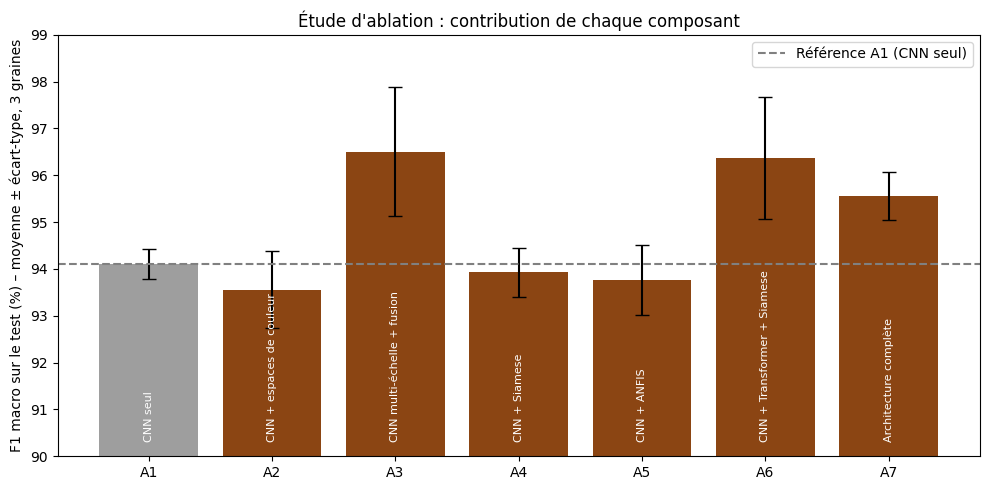

In [13]:
#Graphique de l’ablation

ordre = sorted(moy.index)
couleurs = ["#9E9E9E" if v.startswith("A1") else "#8B4513" for v in ordre]

plt.figure(figsize=(10, 5))
plt.bar([v.split(" – ")[0] for v in ordre], moy.loc[ordre, "F1 (macro)"],
        yerr=ecart.loc[ordre, "F1 (macro)"], capsize=5, color=couleurs)
plt.axhline(moy.loc["A1 – CNN seul", "F1 (macro)"], color="gray", linestyle="--", label="Référence A1 (CNN seul)")
for i, v in enumerate(ordre):
    plt.text(i, 90.3, v.split(" – ")[1], rotation=90, ha="center", va="bottom", fontsize=8, color="white")
plt.ylim(90, 99)
plt.ylabel("F1 macro sur le test (%) – moyenne ± écart-type, 3 graines")
plt.title("Étude d'ablation : contribution de chaque composant")
plt.legend()
plt.tight_layout()
plt.savefig("results/dl/07_ablation.png", dpi=150)
plt.show()

## Conclusion de l'étude d'ablation

**Réponses aux questions scientifiques (F1 macro sur le test, moyenne ± écart-type sur 3 graines, référence A1 = 94,1 ± 0,3 %) :**

1. **L'intégration de plusieurs espaces de couleur améliore-t-elle les performances ?** Non pour le CNN : A2 (RGB + HSV + LAB en entrée, 93,6 ± 0,8 %) ne fait pas mieux que A1. Le CNN apprend lui-même, dès ses premières convolutions, des combinaisons des canaux RGB équivalentes à ces espaces. À l'inverse, la fusion des espaces était bénéfique en machine learning (étape 5), où les classifieurs ne transforment pas leurs entrées.
2. **L'extraction multi-échelle permet-elle de mieux caractériser les fèves ?** Oui : A3 apporte le plus fort gain individuel (+2,4 points, 96,5 %), au prix d'une plus grande instabilité (± 1,4). Ce gain se retrouve dans l'architecture complète : avec un extracteur multi-échelle, le modèle CNN-Transformer-ANFIS passe de 94,3 % (extracteur simple, étape 6) à 95,6 % (A7).
3. **Le réseau siamois améliore-t-il la discrimination ?** Non : A4 (93,9 %) égale A1, et A6 (96,4 %) n'est pas significativement supérieur au même encodeur CNN-Transformer entraîné directement (M5, 95,6 %), alors que l'apprentissage par paires multiplie le temps d'entraînement par 5 à 6.
4. **Le Transformer apporte-t-il un gain par rapport à un CNN classique ?** Oui, dans les deux cadres d'apprentissage : +1,5 point en classification directe (M1 → M5) et +2,5 points en apprentissage siamois (A4 → A6).
5. **L'intégration d'ANFIS améliore-t-elle les performances et l'interprétabilité ?** Pas les performances (A5 : 93,8 %, équivalent à A1), mais l'interprétabilité : la décision se résume à un petit nombre de règles floues, une par catégorie (étape 6).
6. **L'architecture complète est-elle réellement supérieure aux architectures individuelles ?** Non en performance pure : A7 (95,6 ± 0,5 %) reste derrière A3 et A6 (≈ 96,5 %) et derrière ResNet50 (97,1 %). En revanche, elle est la plus stable des variantes performantes (± 0,5 contre ± 1,3 à 1,4), reste rapide à entraîner (5,5 minutes) et est la seule à associer une bonne performance à une décision interprétable.

**Composants les plus utiles :** l'extraction multi-échelle et le Transformer. **Composants sans gain de performance :** les espaces de couleur en entrée du CNN, l'apprentissage siamois et l'ANFIS — ce dernier se justifiant par l'interprétabilité.